# Anexo: ViT-B/16

Faculdade de Ciências e Tecnologias em Engenharia - Campus UnB Gama <br>
Tópicos Especiais em Matemática Aplicada: Deep Learning <br>
Professor: Vinicius Rispoli<br>
Alunos: Eliseu Kadesh, Pedro Barbosa e Raquel Eucaria.

## 1. Dados

Usa a divisão treino/validação/teste em `data/passaros/dataset_split`, criada uma única vez e reutilizada pelos três notebooks. Rode o [notebook 01](01_classificador_vit_h14.ipynb) antes.

In [ ]:
import torch
from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm
import matplotlib.pyplot as plt
import os

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

# Configurar o dispositivo (GPU, se disponível)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Usando dispositivo: {device}")

Usando dispositivo: cuda


In [ ]:
data_dir = "data/passaros/dataset_split"

train_dir = os.path.join(data_dir, 'train')
val_dir = os.path.join(data_dir, 'val')
test_dir = os.path.join(data_dir, 'test')

### Classes

In [ ]:
# Listar as classes (espécies de aves)
classes = sorted(os.listdir(train_dir)) # Ordenar para consistência
num_classes = len(classes)
print(f"Número de classes: {num_classes}")
print("Classes:", classes)


Número de classes: 14
Classes: ['amazona_aestiva', 'amazona_amazonica', 'anodorhynchus_hyacinthinus', 'ara_ararauna', 'ara_chloropterus', 'ara_macao', 'brotogeris_chiriri', 'diopsittaca_nobilis', 'eupsittula_aurea', 'forpus_xanthopterygius', 'orthopsittaca_manilatus', 'primolius_maracana', 'psittacara_leucophthalmus', 'touit_melanonotus']


### Pré-processamento

In [ ]:
IMG_SIZE = 224
BATCH_SIZE = 32

# Médias e desvios padrão da ImageNet
imagenet_mean = [0.485, 0.456, 0.406]
imagenet_std = [0.229, 0.224, 0.225]

# Transformações para os conjuntos de validação e teste (sem data augmentation)
transform_val_test = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

### Data augmentation e DataLoaders

In [ ]:
transform_train = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=imagenet_mean, std=imagenet_std)
])

train_dataset = datasets.ImageFolder(train_dir, transform=transform_train)
val_dataset = datasets.ImageFolder(val_dir, transform=transform_val_test)
test_dataset = datasets.ImageFolder(test_dir, transform=transform_val_test)


train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Tamanho do dataset de treino: {len(train_dataset)} imagens")
print(f"Tamanho do dataset de validação: {len(val_dataset)} imagens")
print(f"Tamanho do dataset de teste: {len(test_dataset)} imagens")

Tamanho do dataset de treino: 2425 imagens
Tamanho do dataset de validação: 304 imagens
Tamanho do dataset de teste: 308 imagens


## 2. Treino

### Funções de treino e avaliação

Adaptadas das funções vistas em aula. A CNN do zero não foi re-treinada neste notebook.

In [ ]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    pbar = tqdm(loader, desc='Treino', leave=False)
    for inputs, targets in pbar:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        outputs = model(inputs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * inputs.size(0)
        _, predicted = outputs.max(1)
        total   += targets.size(0)
        correct += predicted.eq(targets).sum().item()

        pbar.set_postfix({'loss': running_loss / total, 'acc': 100.*correct/total})

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = 100. * correct / total
    return epoch_loss, epoch_acc

def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        pbar = tqdm(loader, desc='Validação', leave=False)
        for inputs, targets in pbar:
            inputs, targets = inputs.to(device), targets.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            running_loss += loss.item() * inputs.size(0)

            _, predicted = outputs.max(1)
            total   += targets.size(0)
            correct += predicted.eq(targets).sum().item()
            pbar.set_postfix({'loss': running_loss/total, 'acc': 100.*correct/total})

    epoch_loss = running_loss / len(loader.dataset)
    epoch_acc  = 100. * correct / total
    return epoch_loss, epoch_acc

### ViT-B/16: extração de características

Pesos da ImageNet congelados; só o novo classificador é treinado, por 10 épocas.

In [ ]:
print("Carregando o modelo ViT-B/16 pré-treinado...")

# Carregar o modelo ViT-B/16 com os pesos da ImageNet
model_vit = models.vit_b_16(weights='IMAGENET1K_V1')

# Congelar os pesos de todas as camadas
for param in model_vit.parameters():
    param.requires_grad = False

# Substituir a camada de classificação (no ViT, chama-se 'heads')
num_ftrs = model_vit.heads.head.in_features
model_vit.heads.head = nn.Linear(num_ftrs, num_classes) # num_classes é 14

# Mover o modelo para a GPU
model_vit = model_vit.to(device)

# Otimizador para treinar APENAS a nova camada de classificação
optimizer_tl_vit = optim.Adam(model_vit.heads.head.parameters(), lr=0.001)
epochs_tl = 10
criterion = nn.CrossEntropyLoss() # Re-definindo o critério para garantir que está disponível

print("\nIniciando Treinamento com Transfer Learning (Feature Extraction) no ViT-B/16...")
for epoch in range(epochs_tl):
    print(f"\nÉpoca {epoch+1}/{epochs_tl}")
    train_loss, train_acc = train_one_epoch(model_vit, train_loader, criterion, optimizer_tl_vit, device)
    val_loss, val_acc = evaluate(model_vit, val_loader, criterion, device)
    print(f"  Loss de Treino: {train_loss:.4f}, Acurácia de Treino: {train_acc:.2f}%")
    print(f"  Loss de Validação: {val_loss:.4f}, Acurácia de Validação: {val_acc:.2f}%")

Carregando o modelo ViT-B/16 pré-treinado...

Iniciando Treinamento com Transfer Learning (Feature Extraction) no ViT-B/16...

Época 1/10
  Loss de Treino: 1.9264, Acurácia de Treino: 38.72%
  Loss de Validação: 1.6362, Acurácia de Validação: 48.36%

Época 2/10
  Loss de Treino: 1.3595, Acurácia de Treino: 58.31%
  Loss de Validação: 1.3868, Acurácia de Validação: 57.89%

Época 3/10
  Loss de Treino: 1.1409, Acurácia de Treino: 66.80%
  Loss de Validação: 1.2912, Acurácia de Validação: 59.54%

Época 4/10
  Loss de Treino: 1.0061, Acurácia de Treino: 71.92%
  Loss de Validação: 1.1779, Acurácia de Validação: 65.46%

Época 5/10
  Loss de Treino: 0.9122, Acurácia de Treino: 73.36%
  Loss de Validação: 1.1329, Acurácia de Validação: 62.17%

Época 6/10
  Loss de Treino: 0.8427, Acurácia de Treino: 75.42%
  Loss de Validação: 1.0821, Acurácia de Validação: 65.79%

Época 7/10
  Loss de Treino: 0.7862, Acurácia de Treino: 77.77%
  Loss de Validação: 1.0553, Acurácia de Validação: 65.46%

Época

### ViT-B/16: fine-tuning

Rede inteira descongelada, lr 1e-5, 15 épocas.

In [ ]:
print("\nDescongelando todas as camadas para o Fine-Tuning...")
# Descongelar todas as camadas para o ajuste fino
for param in model_vit.parameters():
    param.requires_grad = True

# Otimizador para o modelo inteiro com uma taxa de aprendizado bem baixa
optimizer_ft_vit = optim.Adam(model_vit.parameters(), lr=1e-5)
epochs_ft = 15

print("\nIniciando Treinamento com Fine-Tuning no ViT-B/16...")
for epoch in range(epochs_ft):
    print(f"\nÉpoca {epoch+1}/{epochs_ft}")
    train_loss, train_acc = train_one_epoch(model_vit, train_loader, criterion, optimizer_ft_vit, device)
    val_loss, val_acc = evaluate(model_vit, val_loader, criterion, device)
    print(f"  Loss de Treino: {train_loss:.4f}, Acurácia de Treino: {train_acc:.2f}%")
    print(f"  Loss de Validação: {val_loss:.4f}, Acurácia de Validação: {val_acc:.2f}%")


Descongelando todas as camadas para o Fine-Tuning...

Iniciando Treinamento com Fine-Tuning no ViT-B/16...

Época 1/15
  Loss de Treino: 0.5017, Acurácia de Treino: 85.28%
  Loss de Validação: 0.7181, Acurácia de Validação: 75.66%

Época 2/15
  Loss de Treino: 0.3150, Acurácia de Treino: 91.18%
  Loss de Validação: 0.6210, Acurácia de Validação: 80.26%

Época 3/15
  Loss de Treino: 0.2176, Acurácia de Treino: 94.76%
  Loss de Validação: 0.5802, Acurácia de Validação: 80.26%

Época 4/15
  Loss de Treino: 0.1688, Acurácia de Treino: 95.96%
  Loss de Validação: 0.6077, Acurácia de Validação: 79.28%

Época 5/15
  Loss de Treino: 0.1376, Acurácia de Treino: 96.82%
  Loss de Validação: 0.5674, Acurácia de Validação: 83.22%

Época 6/15
  Loss de Treino: 0.0898, Acurácia de Treino: 98.43%
  Loss de Validação: 0.5418, Acurácia de Validação: 84.54%

Época 7/15
  Loss de Treino: 0.0741, Acurácia de Treino: 98.64%
  Loss de Validação: 0.5291, Acurácia de Validação: 83.55%

Época 8/15
  Loss de Tr

## 3. Avaliação no teste interno (308 imagens)

In [ ]:
# Função para obter predições e rótulos do conjunto de teste
def get_predictions(model, loader, device):
    model.eval()
    all_preds = torch.tensor([]).to(device)
    all_labels = torch.tensor([]).to(device)
    with torch.no_grad():
        for inputs, labels in tqdm(loader, desc="Avaliando no Teste"):
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            _, preds = torch.max(outputs, 1)
            all_preds = torch.cat((all_preds, preds), dim=0)
            all_labels = torch.cat((all_labels, labels), dim=0)
    return all_labels.cpu().numpy(), all_preds.cpu().numpy()

class_names = train_dataset.classes


--- Relatório de Classificação: Modelo ViT-B/16 com Fine-Tuning ---
                            precision    recall  f1-score   support

           amazona_aestiva       0.80      0.80      0.80        25
         amazona_amazonica       0.89      0.76      0.82        21
anodorhynchus_hyacinthinus       0.93      1.00      0.96        25
              ara_ararauna       0.95      0.84      0.89        25
          ara_chloropterus       0.88      1.00      0.94        22
                 ara_macao       1.00      0.86      0.93        22
        brotogeris_chiriri       0.70      0.70      0.70        20
       diopsittaca_nobilis       0.81      0.71      0.76        24
          eupsittula_aurea       0.71      0.91      0.80        22
    forpus_xanthopterygius       0.82      0.82      0.82        22
   orthopsittaca_manilatus       0.69      0.90      0.78        20
        primolius_maracana       0.82      0.82      0.82        22
 psittacara_leucophthalmus       0.82      0.6

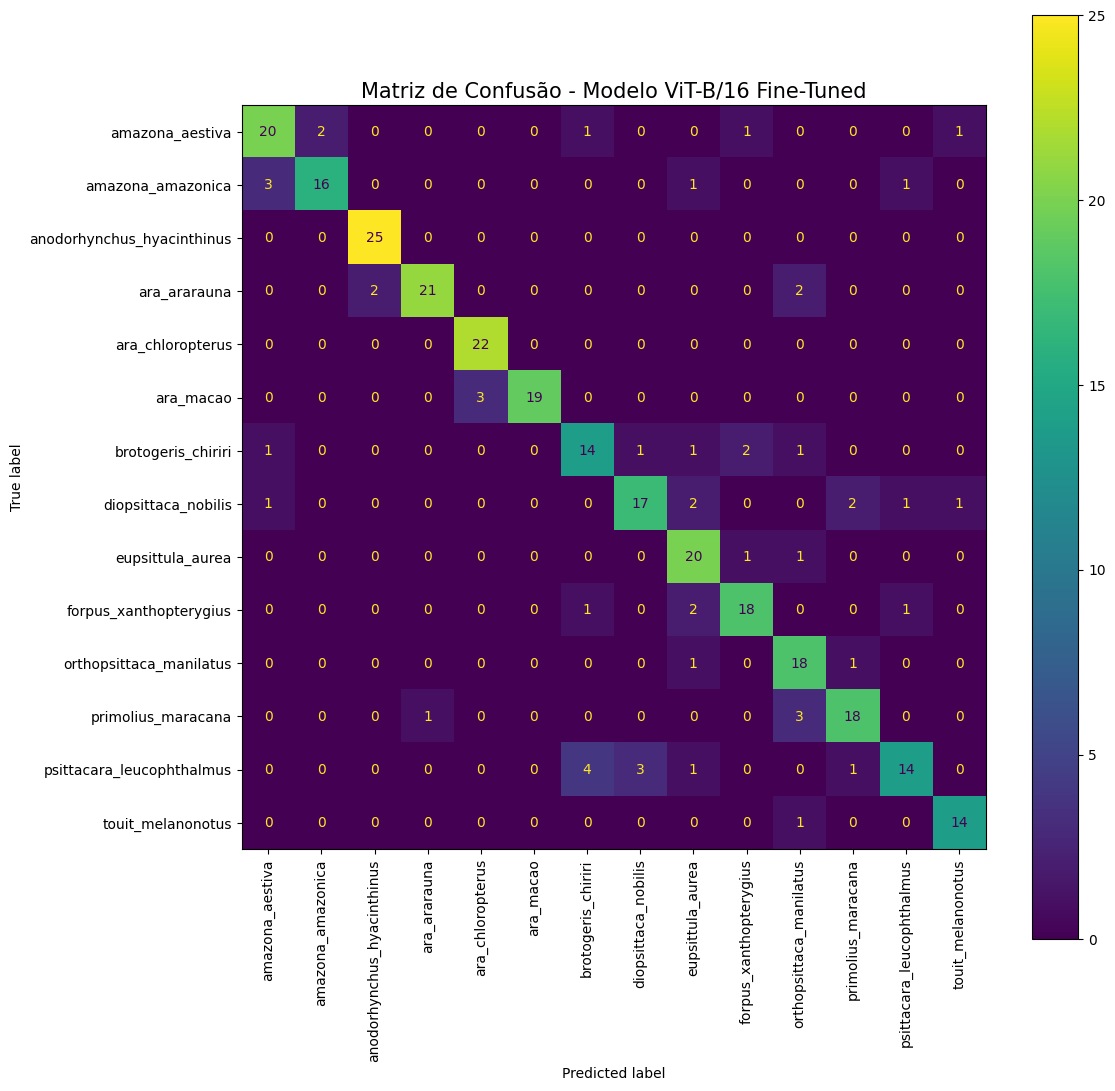

In [ ]:
def plot_confusion_matrix(labels, preds, class_names, title):
    """Função para plotar a matriz de confusão."""
    cm = confusion_matrix(labels, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

    fig, ax = plt.subplots(figsize=(12, 12))
    disp.plot(ax=ax, xticks_rotation='vertical', cmap='viridis')
    ax.set_title(title, fontsize=15)
    plt.show()

print("\n--- Relatório de Classificação: Modelo ViT-B/16 com Fine-Tuning ---")
labels_vit, preds_vit = get_predictions(model_vit, test_loader, device)
print(classification_report(labels_vit, preds_vit, target_names=class_names))

plot_confusion_matrix(labels_vit, preds_vit, class_names, 'Matriz de Confusão - Modelo ViT-B/16 Fine-Tuned')